# 06 — Q5: frequência de interação × evolução do desempenho

**CRISP-DM, fases 4 e 5** · corresponde à seção **§7.3** de `docs/DOCUMENTACAO.md` e ao problema 2 da §13

> **Q5 — Existe relação entre a frequência de acesso/interação e a evolução do desempenho dos estudantes?**

Neste notebook:
1. As fórmulas de evolução de cada base e por que **não são comparáveis em escala**
2. ARES: pré → pós, correlações, ganho normalizado, regressão à média
3. EdNet: fluxo de estudantes (297.915 → 42.720), demonstração do erro da fórmula antiga e resultado corrigido
4. Conclusão em quatro níveis e conferência com os resultados oficiais

In [1]:
import sys, json, warnings
from pathlib import Path

# encontra a raiz do projeto (pasta que contém src/config.py), venha o notebook de onde vier
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

import config as C
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Projeto:", ROOT)
from scipy import stats
from utils import spearman, partial_spearman, groups_test, quartiles

Projeto: C:\Users\braia\OneDrive\Documentos\GitHub\Datasets-Beready


## 1. As duas fórmulas

| | ARES | EdNet |
|---|---|---|
| Fórmula | `nota_pos − nota_pre` | `acurácia(últimas 20) − acurácia(primeiras 20)`, **só questões fora do diagnóstico** |
| Escala | pontos, de −11 a +11 | proporção de acertos, de −1 a +1 (mostrada em p.p.) |
| Instrumento | Duas provas fixas de 12 itens (Q9 fora da nota), iguais para todos | Questões diferentes para cada aluno, escolhidas pelo app |
| Quem entra | 141 alunos com as duas provas e log | Estudantes com ≥ 40 questões fora do diagnóstico |

➡️ “+0,71 ponto” (ARES) e “+1,0 p.p.” (EdNet) **medem coisas diferentes** e não se comparam. Entre as bases, compara-se só a **direção e a ordem de grandeza** da correlação.

## 2. ARES

In [2]:
a = pd.read_csv(C.PROCESSED / "ares_alunos.csv")
perf = a[a["n_interacoes"] > 0].dropna(subset=["nota_pre", "nota_pos"]).copy()
perf["evolucao_calc"] = perf["nota_pos"] - perf["nota_pre"]
assert (perf["evolucao_calc"] == perf["evolucao"]).all()
print(f"Alunos: {len(perf)} | média pré {perf['nota_pre'].mean():.2f} → pós {perf['nota_pos'].mean():.2f} "
      f"(evolução média {perf['evolucao'].mean():+.2f} ponto)")
w = stats.wilcoxon(perf["nota_pos"], perf["nota_pre"])
print(f"Wilcoxon pareado (pós × pré): p = {w.pvalue:.3f}  ({(perf['evolucao'] == 0).sum()} diferenças zero são descartadas pelo teste)")
print("Melhoraram / iguais / pioraram:",
      f"{(perf['evolucao'] > 0).mean():.1%} / {(perf['evolucao'] == 0).mean():.1%} / {(perf['evolucao'] < 0).mean():.1%}")

Alunos: 141 | média pré 4.75 → pós 5.46 (evolução média +0.71 ponto)
Wilcoxon pareado (pós × pré): p = 0.011  (20 diferenças zero são descartadas pelo teste)
Melhoraram / iguais / pioraram: 46.8% / 14.2% / 39.0%


A turma melhora em média (p = 0,011). A pergunta, porém, é se **quem interage mais melhora mais**:

In [3]:
FREQ = {"n_interacoes": "Nº de interações", "n_sessoes": "Nº de sessões", "dias_ativos": "Dias ativos", "n_logins": "Nº de logins"}
linhas = []
for c, n in FREQ.items():
    s = spearman(perf[c], perf["evolucao"], boot=1000)
    linhas.append({"métrica": n, "ρ com a evolução": s["rho"], "IC95%": s["ic95"], "p": round(s["p"], 3),
                   "ρ com o ganho normalizado": spearman(perf[c], perf["ganho_normalizado"], boot=0)["rho"],
                   "ρ parcial (controle do pré)": partial_spearman(perf[c], perf["evolucao"], perf["nota_pre"])["rho_parcial"]})
pd.DataFrame(linhas)

,métrica,ρ com a evolução,IC95%,p,ρ com o ganho normalizado,ρ parcial (controle do pré)
0,Nº de interações,0.0010,"[-0.1659, 0.1769]",0.991,-0.0166,0.0227
1,Nº de sessões,0.0301,"[-0.1433, 0.2]",0.723,0.0572,0.0620
2,Dias ativos,0.0091,"[-0.1731, 0.1879]",0.915,0.0105,0.0289
3,Nº de logins,0.0301,"[-0.1403, 0.1904]",0.723,0.0183,-0.0130


### 2.1 Ganho normalizado: por que é só complementar

In [4]:
print("Alunos com pré = 11 (ganho indefinido, divisão por zero):", int((perf["nota_pre"] == 11).sum()))
print("Menor ganho normalizado:", perf["ganho_normalizado"].min(), "(não tem limite inferior)")
print(f"% com ganho negativo: {(perf['ganho_normalizado'] < 0).mean():.1%}")

Alunos com pré = 11 (ganho indefinido, divisão por zero): 2
Menor ganho normalizado: -7.0 (não tem limite inferior)
% com ganho negativo: 38.3%


### 2.2 Regressão à média

Quem começa com nota baixa tende a subir, e quem começa alta tende a cair, mesmo sem nenhum efeito real. Por isso também é feita a análise **controlando o pré-teste**.

ρ(nota pré, evolução) = -0.32


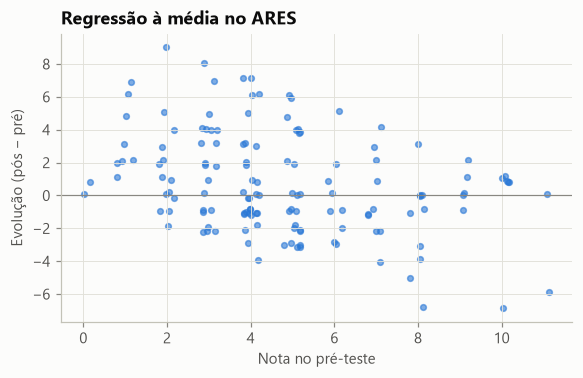

In [5]:
print(f"ρ(nota pré, evolução) = {stats.spearmanr(perf['nota_pre'], perf['evolucao'])[0]:+.2f}")
fig, ax = plt.subplots(figsize=(6, 3.4))
rng = np.random.default_rng(0)
ax.scatter(perf["nota_pre"] + rng.uniform(-.2, .2, len(perf)), perf["evolucao"] + rng.uniform(-.2, .2, len(perf)), s=14, color="#2a78d6", alpha=.6)
ax.axhline(0, color="#898781", lw=.8)
ax.set_xlabel("Nota no pré-teste"); ax.set_ylabel("Evolução (pós − pré)")
ax.set_title("Regressão à média no ARES")
plt.show()

In [6]:
perf["quartil"] = quartiles(perf["n_interacoes"])
tab = perf.groupby("quartil", observed=True).agg(pre=("nota_pre", "mean"), pos=("nota_pos", "mean"), evolucao=("evolucao", "mean"),
                                                 pct_melhorou=("evolucao", lambda s: (s > 0).mean() * 100))
display(tab.round(2))
g = groups_test(perf, "quartil", "evolucao")
print(f"Kruskal-Wallis: p = {g['kruskal_p']:.2f} | δ de Cliff 4º × 1º = {g['cliffs_delta_alto_vs_baixo']:+.3f}")

,pre,pos,evolucao,pct_melhorou
quartil,,,,
1º quartil (menos),4.58,5.86,1.28,61.11
2º quartil,4.37,4.09,-0.29,31.43
3º quartil,5.20,5.74,0.54,40.00
4º quartil (mais),4.86,6.14,1.29,54.29


Kruskal-Wallis: p = 0.10 | δ de Cliff 4º × 1º = -0.002


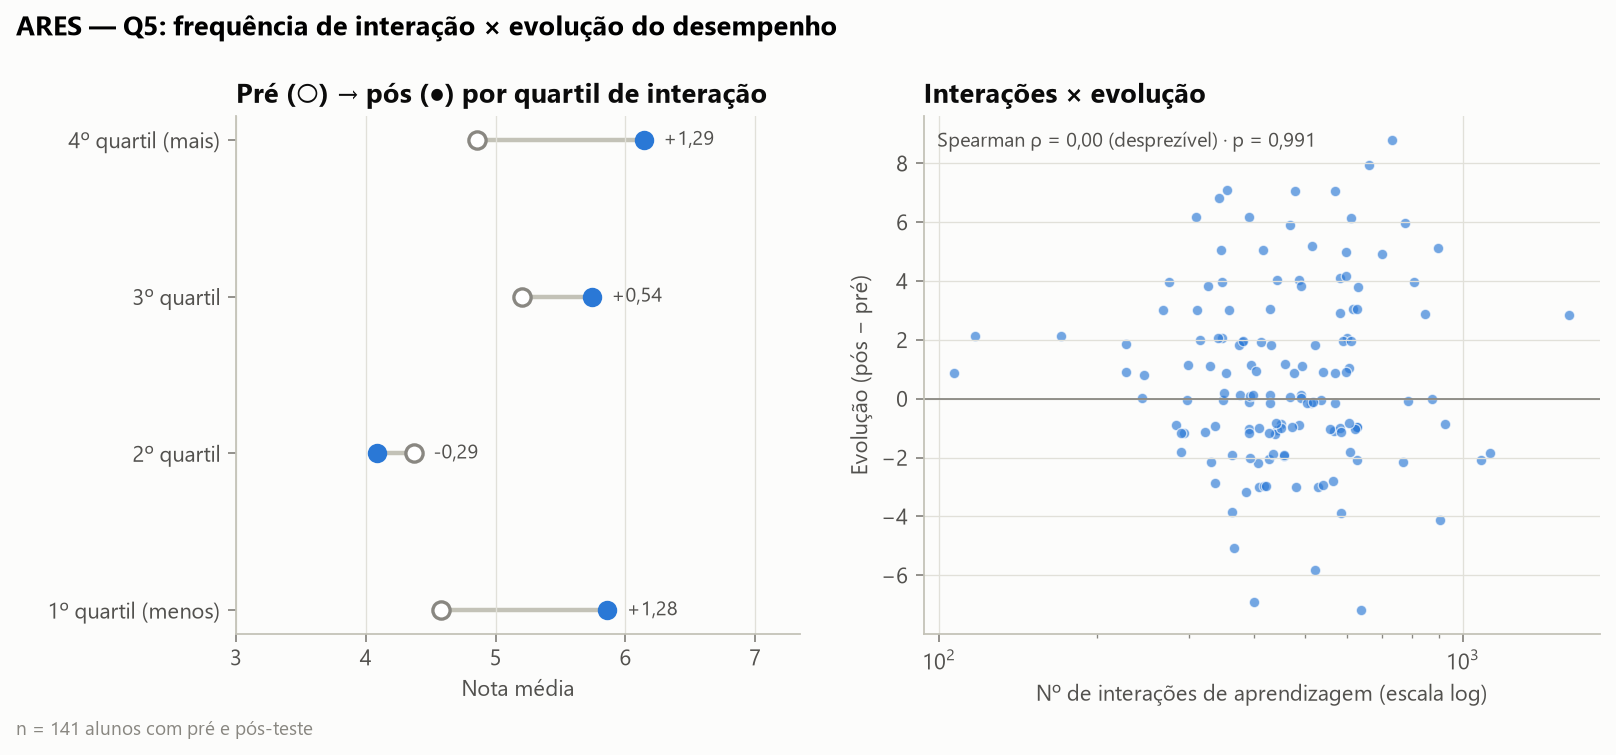

In [7]:
Image(filename=str(C.FIG / "ares" / "Q5_interacao_evolucao.png"))

## 3. EdNet

### 3.1 Quem entra na análise

A base inteira tem 297.915 estudantes, todos processados. Para medir evolução, são necessárias **20 questões de prática no início e 20 no fim**. Cada etapa tem o seu denominador:

In [8]:
u = pd.read_csv(C.PROCESSED / "ednet_users.csv.gz")
nd = u["n_respondidas"] - u["resp_diagnosis"]
u["evolucao"] = u["acuracia_fim_sem_diag"] - u["acuracia_inicio_sem_diag"]
fluxo = pd.DataFrame([
    ("Base original (todos os arquivos do KT3)", len(u)),
    ("Com ≥ 1 resposta final corrigível", int((u["n_respondidas"] > 0).sum())),
    ("Com ≥ 1 resposta fora do diagnóstico", int((nd > 0).sum())),
    ("Com ≥ 40 respostas de qualquer origem (fórmula ANTIGA)", int((u["n_respondidas"] >= 40).sum())),
    ("Com ≥ 40 respostas fora do diagnóstico", int((nd >= 40).sum())),
    ("Com evolução calculada (amostra final da Q5)", int(u["evolucao"].notna().sum())),
], columns=["etapa", "estudantes"])
fluxo["estudantes"] = fluxo["estudantes"].map(lambda v: f"{v:,}".replace(",", "."))
fluxo

,etapa,estudantes
0,Base original (todos os arquivos do KT3),297.915
1,Com ≥ 1 resposta final corrigível,296.700
2,Com ≥ 1 resposta fora do diagnóstico,102.691
3,Com ≥ 40 respostas de qualquer origem (fórmula ANTIGA),46.635
4,Com ≥ 40 respostas fora do diagnóstico,42.720
5,Com evolução calculada (amostra final da Q5),42.720


Os 42.720 que entram respondem **pelo menos 40 questões de prática**, então são **mais engajados que a média** (viés de seleção). O resultado não vale automaticamente para quem usa pouco.

### 3.2 O erro da fórmula antiga, demonstrado

A primeira versão usava as primeiras e últimas 20 respostas **de qualquer origem**. Numa **amostra aleatória de 3.000** estudantes (com ≥ 40 respostas), medimos quanto de cada janela era diagnóstico:

In [9]:
import io
import ednet_01_extract as X

if C.EDNET_BRUTO_DISPONIVEL:
    gab = pd.read_csv(C.EDNET_QUESTIONS, usecols=["question_id", "correct_answer"]).set_index("question_id")["correct_answer"]
    amostra = u[u["n_respondidas"] >= 40].sample(3000, random_state=42)["user_id"]
    linhas = []
    for uid in amostra:
        d = X.ler_estudante(uid).drop_duplicates()
        d["timestamp"] = d["timestamp"].astype("int64")
        d = d.sort_values("timestamp", kind="stable")
        act = d["action_type"].to_numpy()
        d["seg"] = np.concatenate([[0], np.cumsum(act[:-1] == "submit")])
        r = d[(d["action_type"] == "respond") & d["seg"].isin(set(d["seg"][act == "submit"]))]
        r = r.drop_duplicates(["seg", "item_id"], keep="last")
        r = r[r["item_id"].isin(gab.index)]
        c = (r["user_answer"].to_numpy() == gab[r["item_id"]].to_numpy())
        s = r["source"].to_numpy()
        linhas.append({"diag_na_janela_inicial": (s[:20] == "diagnosis").mean(),
                       "diag_na_janela_final": (s[-20:] == "diagnosis").mean(),
                       "evolucao_formula_antiga": c[-20:].mean() - c[:20].mean()})
    demo = pd.DataFrame(linhas)
    print(f"% de questões do diagnóstico na janela INICIAL: {demo['diag_na_janela_inicial'].mean():.1%}")
    print(f"% de questões do diagnóstico na janela FINAL:   {demo['diag_na_janela_final'].mean():.1%}")
else:
    print("EdNet bruto não disponível: a demonstração por amostra precisa dos arquivos originais.")
    print("Resultado registrado na documentação (§13, problema 2): 36% na janela inicial × 0,5% na final.")

% de questões do diagnóstico na janela INICIAL: 36.4%
% de questões do diagnóstico na janela FINAL:   0.5%


➡️ A janela inicial tinha **~36% de diagnóstico** (mais difícil: 47% de acerto, contra 66% na prática), e a final, quase nenhum. A “evolução” comparava provas diferentes. Comparação das duas fórmulas na base inteira:

In [10]:
antiga = (u["acuracia_fim"] - u["acuracia_inicio"]).dropna()
nova = u["evolucao"].dropna()
pd.DataFrame({
    "fórmula ANTIGA (qualquer origem)": [len(antiga), u["acuracia_inicio"].mean(), u["acuracia_fim"].mean(), antiga.mean(), antiga.median(), (antiga > 0).mean()],
    "fórmula CORRIGIDA (sem diagnóstico)": [len(nova), u["acuracia_inicio_sem_diag"].mean(), u["acuracia_fim_sem_diag"].mean(), nova.mean(), nova.median(), (nova > 0).mean()],
}, index=["estudantes", "acurácia início", "acurácia fim", "evolução média", "evolução mediana", "% que melhorou"]).round(4)

,fórmula ANTIGA (qualquer origem),fórmula CORRIGIDA (sem diagnóstico)
estudantes,46635.0000,42720.0000
acurácia início,0.5855,0.6362
acurácia fim,0.6441,0.6462
evolução média,0.0586,0.0100
evolução mediana,0.0500,0.0000
% que melhorou,0.5851,0.4716


### 3.3 Correlações (fórmula corrigida)

In [11]:
ev = u.dropna(subset=["evolucao"]).copy()
ev_diag = u.copy()
ev_diag["acc_diag"] = np.where(u["resp_diagnosis"] >= 5, u["acerto_diagnosis"] / u["resp_diagnosis"].clip(lower=1), np.nan)
ev_diag["acc_pos"] = np.where(nd >= 10, (u["n_acertos"] - u["acerto_diagnosis"]) / nd.clip(lower=1), np.nan)
ev_diag["evol_alt"] = ev_diag["acc_pos"] - ev_diag["acc_diag"]
ev_diag = ev_diag.dropna(subset=["evol_alt"])
linhas = []
for c, n in {"n_eventos": "Nº de interações", "n_sessoes": "Nº de sessões", "dias_ativos": "Dias ativos"}.items():
    s = spearman(ev[c], ev["evolucao"], boot=200)
    linhas.append({"métrica": n, "ρ": s["rho"], "IC95%": s["ic95"], "p": f"{s['p']:.1e}", "força": s["forca"],
                   "ρ parcial (controle do início)": partial_spearman(ev[c], ev["evolucao"], ev["acuracia_inicio_sem_diag"])["rho_parcial"],
                   f"ρ alternativo (pós-diag − diag, n={len(ev_diag)})": round(stats.spearmanr(ev_diag[c], ev_diag["evol_alt"])[0], 4)})
pd.DataFrame(linhas)

,métrica,ρ,IC95%,p,força,ρ parcial (controle do início),"ρ alternativo (pós-diag − diag, n=66062)"
0,Nº de interações,0.0393,"[0.0248, 0.0524]",4.4e-16,desprezível,0.0586,0.0665
1,Nº de sessões,0.0233,"[0.01, 0.0374]",1.5e-06,desprezível,0.0098,0.0409
2,Dias ativos,0.0223,"[0.0089, 0.036]",4.0e-06,desprezível,-0.0033,0.0422


In [12]:
ev["quartil"] = quartiles(ev["n_eventos"])
display(ev.groupby("quartil", observed=True)["evolucao"].agg(evolucao_media_pp=lambda s: s.mean() * 100,
                                                             pct_melhorou=lambda s: (s > 0).mean() * 100).round(1))
g = groups_test(ev, "quartil", "evolucao")
print(f"δ de Cliff 4º × 1º quartil = {g['cliffs_delta_alto_vs_baixo']:+.3f} (desprezível)")
print(f"Regressão à média: ρ(início, evolução) = {stats.spearmanr(ev['acuracia_inicio_sem_diag'], ev['evolucao'])[0]:+.2f}")
print(f"Variância da evolução 'explicada' pelo nº de interações: ρ² = {spearman(ev['n_eventos'], ev['evolucao'], boot=0)['rho'] ** 2:.2%}")

,evolucao_media_pp,pct_melhorou
quartil,,
1º quartil (menos),0.3,45.5
2º quartil,0.8,46.6
3º quartil,0.7,46.8
4º quartil (mais),2.2,49.8


δ de Cliff 4º × 1º quartil = +0.057 (desprezível)
Regressão à média: ρ(início, evolução) = -0.60
Variância da evolução 'explicada' pelo nº de interações: ρ² = 0.15%


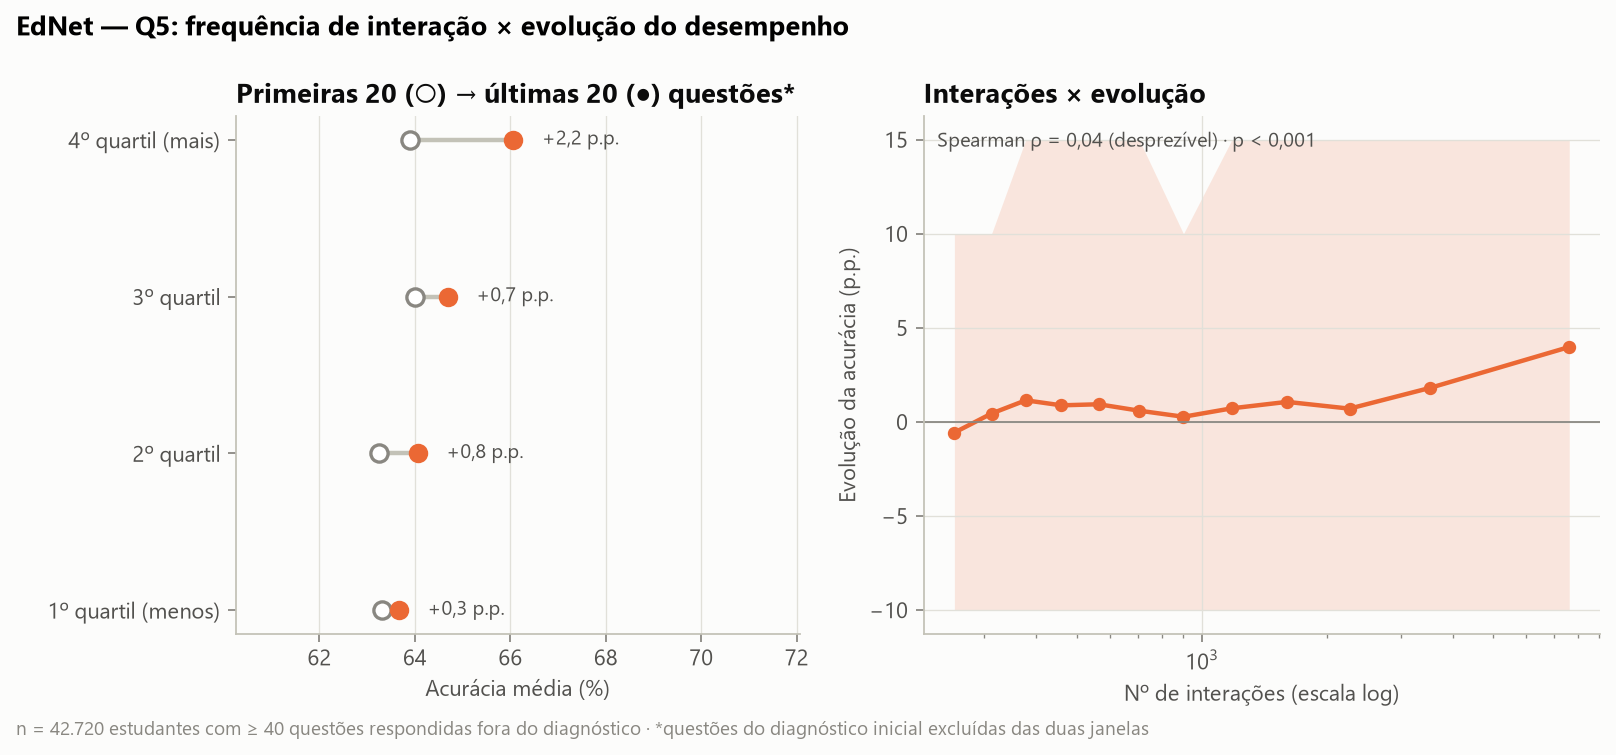

In [13]:
Image(filename=str(C.FIG / "ednet" / "Q5_interacao_evolucao.png"))

## 4. Conclusão da Q5

| | ARES (n = 141) | EdNet (n = 42.720) |
|---|---|---|
| **Observado** | ρ = 0,00 entre interações e (pós − pré) | ρ = +0,04 entre interações e evolução; evolução média +1,0 p.p. (mediana 0) |
| **Significância** | Não significativo (p = 0,99) | Significativo (p < 0,001), **só pelo tamanho da amostra** |
| **Magnitude** | Desprezível; IC95% (−0,16 a +0,17) não descarta efeito fraco | **Desprezível**: explica ~0,2% da variação |
| **Causa?** | — | — |

**Resposta:** **não há associação de relevância prática** entre interagir mais e evoluir mais, em nenhuma das duas bases. No ARES, “não detectado” não é o mesmo que “não existe”: a amostra só detectaria efeitos a partir de ~0,24.

In [14]:
R_A = json.loads((C.TAB / "ares_resultados.json").read_text(encoding="utf-8"))
R_E = json.loads((C.TAB / "ednet_resultados.json").read_text(encoding="utf-8"))
conf = {
    "ARES ρ interações × evolução": (R_A["Q5"]["correlacoes_evolucao"]["n_interacoes"]["rho"], stats.spearmanr(perf["n_interacoes"], perf["evolucao"])[0]),
    "EdNet n": (R_E["Q5"]["populacao"], len(ev)),
    "EdNet acurácia início": (R_E["Q5"]["media_inicio_fim"]["inicio"], ev["acuracia_inicio_sem_diag"].mean()),
    "EdNet acurácia fim": (R_E["Q5"]["media_inicio_fim"]["fim"], ev["acuracia_fim_sem_diag"].mean()),
    "EdNet ρ interações × evolução": (R_E["Q5"]["correlacoes_evolucao"]["n_eventos"]["rho"], stats.spearmanr(ev["n_eventos"], ev["evolucao"])[0]),
}
tab = pd.DataFrame(conf, index=["oficial", "este notebook"]).T
tab["confere"] = np.isclose(tab["oficial"].astype(float), tab["este notebook"].astype(float), atol=1e-3)
display(tab)
assert tab["confere"].all()
print("✅ Os números deste notebook são os mesmos da documentação e dos resultados oficiais.")

,oficial,este notebook,confere
ARES ρ interações × evolução,0.0010,0.000994,True
EdNet n,42720.0000,42720.000000,True
EdNet acurácia início,0.6362,0.636176,True
EdNet acurácia fim,0.6462,0.646191,True
EdNet ρ interações × evolução,0.0393,0.039303,True


✅ Os números deste notebook são os mesmos da documentação e dos resultados oficiais.


**Próximo:** `07_Q10_atividades.ipynb`.